# Camada Gold - Análise de Viagens a Serviço (2025, 1º semestre)

**Pipeline:** `Raw` (cópia fiel do CSV) -> `Silver` (limpa e tipada) -> **`Gold`** (métricas de negócio).

Este notebook tem duas partes:
1. **Parte A** - 3 perguntas respondidas direto na **Silver** (SQL + tabela + gráfico).
2. **Parte B** - Criação da **Gold agregada** (`JOIN` + `GROUP BY`, como *tabela* e como *VIEW*) e as outras 4 perguntas, com 3 gráficos.

> Pré-requisito: executar `0_criar_banco.sql`, `1_extrair.py` e `2_transformar.py`.

In [1]:
import textwrap

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sqlalchemy import text

from banco import get_engine

engine = get_engine()
pd.options.display.float_format = "{:,.2f}".format


def consultar(sql):
    """Executa um SELECT e devolve um DataFrame."""
    return pd.read_sql(text(sql), engine)


def moeda(x, _pos=None):
    """Formata número como R$ 1.234.567 (para os eixos)."""
    return f"R$ {x:,.0f}".replace(",", ".")


def barras_h(df, x, y, titulo, xlabel, ylabel, legenda, cor="#1f77b4",
             formato_moeda=True, largura_rotulo=35):
    """Gráfico de barras horizontais com título, eixos nomeados e legenda.

    Os nomes longos do eixo Y são quebrados em várias linhas e a altura da
    figura cresce com o número de barras, para os rótulos não se sobreporem.
    """
    rotulos = [textwrap.fill(str(r), width=largura_rotulo) for r in df[y]]
    altura = max(5, 0.9 * len(df) + 1.5)

    fig, ax = plt.subplots(figsize=(12, altura))
    ax.barh(rotulos, df[x], color=cor, label=legenda)
    ax.invert_yaxis()  # maior valor no topo
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="y", labelsize=9)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))  # menos números no eixo X
    if formato_moeda:
        ax.xaxis.set_major_formatter(FuncFormatter(moeda))
    ax.legend(loc="lower right")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()

## Verificação rápida da Silver
Conferimos se as tabelas têm dados antes de analisar.

In [2]:
consultar("""
    SELECT 'silver_viagem' AS tabela, COUNT(*) AS linhas FROM silver_viagem
    UNION ALL SELECT 'silver_pagamento', COUNT(*) FROM silver_pagamento
    UNION ALL SELECT 'silver_passagem',  COUNT(*) FROM silver_passagem
    UNION ALL SELECT 'silver_trecho',    COUNT(*) FROM silver_trecho
""")

,tabela,linhas
0,silver_viagem,341860
1,silver_pagamento,606916
2,silver_passagem,167260
3,silver_trecho,763349


# Parte A - Perguntas respondidas na camada Silver

## A1. Quais são os 5 órgãos com maior custo total?
- **Órgão** = `nome_orgao_superior` (órgão ao qual a viagem pertence).
- **Custo total** = soma de `valor_total` (diárias + passagens + outros gastos - devolução).

In [3]:
sql_a1 = """
    SELECT nome_orgao_superior,
           COUNT(*)                     AS qtd_viagens,
           ROUND(SUM(valor_total), 2)   AS custo_total
    FROM silver_viagem
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC
    LIMIT 5
"""
df_a1 = consultar(sql_a1)
df_a1

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486,933,121.65"
1,Ministério da Defesa,61912,"156,070,304.49"
2,Ministério da Educação,65295,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49,697,710.16"
4,Ministério da Previdência Social,8190,"40,417,309.06"


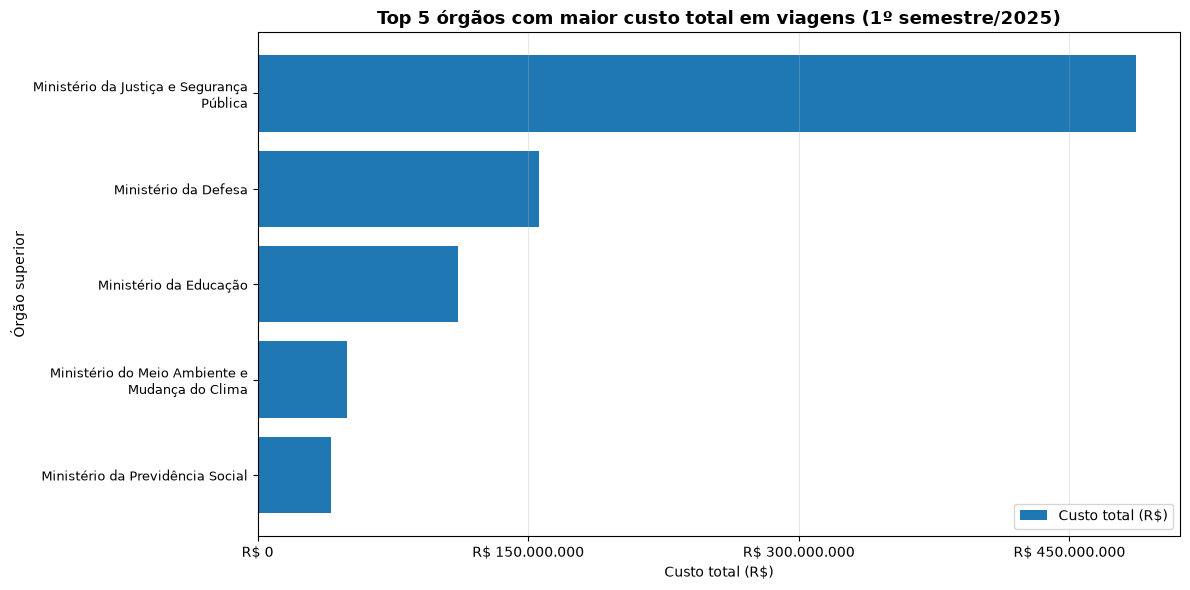

In [4]:
barras_h(df_a1, x="custo_total", y="nome_orgao_superior",
         titulo="Top 5 órgãos com maior custo total em viagens (1º semestre/2025)",
         xlabel="Custo total (R$)", ylabel="Órgão superior",
         legenda="Custo total (R$)")

## A2. Quais são os 3 destinos com maior custo médio por viagem?
- Usa a coluna `destinos` de `silver_viagem`.
- `HAVING COUNT(*) >= 5`: ignora destinos com poucas viagens, para que **um único caso extremo** não pareça "o destino mais caro". Ajuste o limite se quiser.

In [5]:
sql_a2 = """
    SELECT destinos,
           COUNT(*)                     AS qtd_viagens,
           ROUND(AVG(valor_total), 2)   AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    HAVING COUNT(*) >= 5
    ORDER BY custo_medio DESC
    LIMIT 3
"""
df_a2 = consultar(sql_a2)
df_a2

,destinos,qtd_viagens,custo_medio
0,"Brasília/DF, Brasília/DF, Brasília/DF, Brasíli...",5,"114,692.39"
1,"Brasília/DF, Brasília/DF, Brasília/DF, Brasíli...",13,"114,142.97"
2,"Brasília/DF, Brasília/DF, Brasília/DF, Brasíli...",26,"109,081.97"


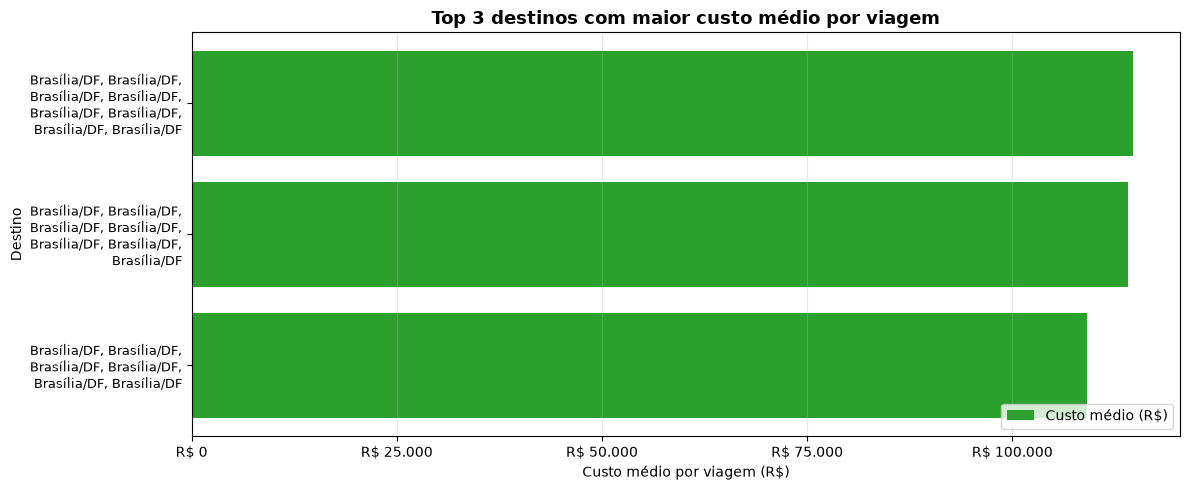

In [6]:
barras_h(df_a2, x="custo_medio", y="destinos",
         titulo="Top 3 destinos com maior custo médio por viagem",
         xlabel="Custo médio por viagem (R$)", ylabel="Destino",
         legenda="Custo médio (R$)", cor="#2ca02c")

## A3. Qual a viagem de maior duração e qual o seu custo total?
`duracao_dias` foi calculado na Silver (`data_fim - data_inicio + 1`).

In [7]:
sql_a3 = """
    SELECT id_viagem, nome_orgao_superior, data_inicio, data_fim,
           duracao_dias, valor_total
    FROM silver_viagem
    WHERE duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 10
"""
df_a3 = consultar(sql_a3)
print("Viagem de maior duração:")
df_a3.head(1)

Viagem de maior duração:


,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00


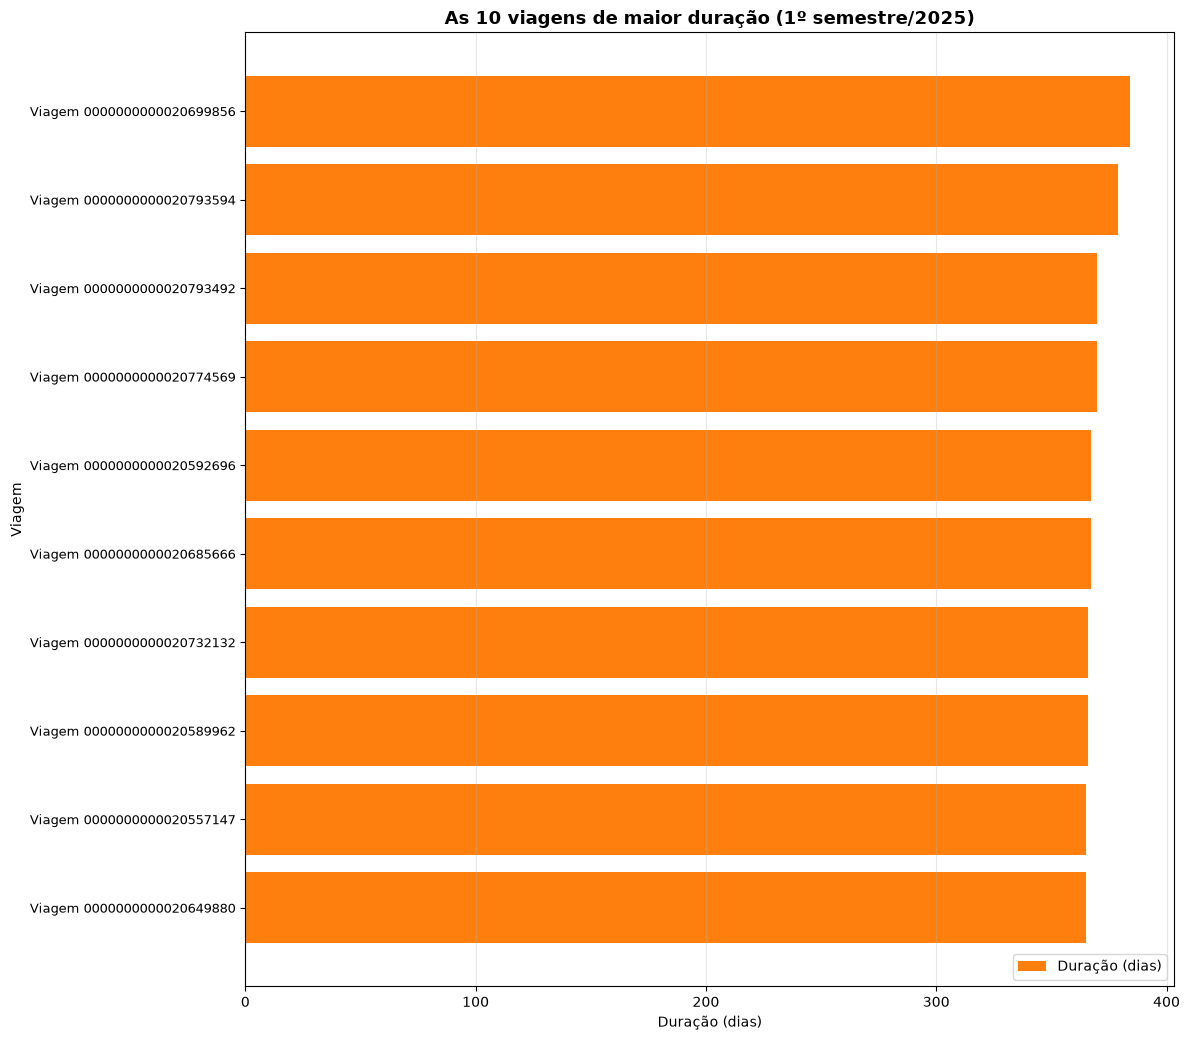

In [8]:
# Gráfico: as 10 viagens mais longas (a 1ª barra é a resposta da pergunta)
df_plot = df_a3.copy()
df_plot["rotulo"] = "Viagem " + df_plot["id_viagem"].astype(str)
barras_h(df_plot, x="duracao_dias", y="rotulo",
         titulo="As 10 viagens de maior duração (1º semestre/2025)",
         xlabel="Duração (dias)", ylabel="Viagem",
         legenda="Duração (dias)", cor="#ff7f0e", formato_moeda=False)

# Parte B - Camada Gold agregada

A Gold guarda **resultados já agregados** (prontos para consumo). Cada agregação usa `JOIN` com
`silver_viagem` (garante que só entram registros de viagens válidas) + `GROUP BY`.

Cada uma é criada de **duas formas**:
- **TABELA** `gold_*` - resultado materializado (rápido de ler; precisa ser recriada se a Silver mudar).
- **VIEW** `vw_gold_*` - consulta salva (sempre atualizada; recalcula a cada leitura).

In [9]:
GOLD = {
    # Pergunta: qual tipo de pagamento tem maior valor médio?
    "gold_tipo_pagamento": """
        SELECT p.tipo_pagamento,
               COUNT(*)                 AS qtd_pagamentos,
               ROUND(SUM(p.valor), 2)   AS valor_total,
               ROUND(AVG(p.valor), 2)   AS valor_medio
        FROM silver_pagamento p
        JOIN silver_viagem v ON v.id_viagem = p.id_viagem
        GROUP BY p.tipo_pagamento
    """,
    # Pergunta: qual órgão pagou mais no total?
    "gold_orgao_pagador": """
        SELECT p.nome_orgao_pagador,
               COUNT(DISTINCT p.id_viagem) AS qtd_viagens,
               ROUND(SUM(p.valor), 2)      AS valor_total_pago
        FROM silver_pagamento p
        JOIN silver_viagem v ON v.id_viagem = p.id_viagem
        GROUP BY p.nome_orgao_pagador
    """,
    # Pergunta: qual meio de transporte é mais usado nos trechos?
    "gold_transporte_trecho": """
        SELECT t.meio_transporte,
               COUNT(*)                    AS qtd_trechos,
               COUNT(DISTINCT t.id_viagem) AS qtd_viagens
        FROM silver_trecho t
        JOIN silver_viagem v ON v.id_viagem = t.id_viagem
        GROUP BY t.meio_transporte
    """,
    # Pergunta: qual UF de destino aparece em mais trechos?
    "gold_uf_destino": """
        SELECT t.destino_uf,
               COUNT(*)                    AS qtd_trechos,
               COUNT(DISTINCT t.id_viagem) AS qtd_viagens
        FROM silver_trecho t
        JOIN silver_viagem v ON v.id_viagem = t.id_viagem
        GROUP BY t.destino_uf
    """,
}

with engine.begin() as conn:  # begin() = transação com commit automático
    for nome, select_sql in GOLD.items():
        conn.execute(text(f"DROP VIEW IF EXISTS vw_{nome}"))
        conn.execute(text(f"DROP TABLE IF EXISTS {nome}"))
        conn.execute(text(f"CREATE TABLE {nome} AS {select_sql}"))
        conn.execute(text(f"CREATE VIEW vw_{nome} AS {select_sql}"))
        print(f"Criadas: {nome} (tabela) e vw_{nome} (view)")

Criadas: gold_tipo_pagamento (tabela) e vw_gold_tipo_pagamento (view)
Criadas: gold_orgao_pagador (tabela) e vw_gold_orgao_pagador (view)
Criadas: gold_transporte_trecho (tabela) e vw_gold_transporte_trecho (view)
Criadas: gold_uf_destino (tabela) e vw_gold_uf_destino (view)


## B1. Qual tipo de pagamento tem o maior valor médio?
Resposta em tabela (a pergunta compara poucos tipos, a tabela já deixa claro o ranking).

In [10]:
df_b1 = consultar("SELECT * FROM gold_tipo_pagamento ORDER BY valor_medio DESC")
df_b1

,tipo_pagamento,qtd_pagamentos,valor_total,valor_medio
0,DIÁRIAS,401463,"834,352,643.52","2,078.28"
1,PASSAGEM,188985,"354,978,915.13","1,878.34"
2,Serviço correlato: seguro,4894,"2,190,136.71",447.51
3,RESTITUIÇÃO,11574,"2,843,762.01",245.70


## B2. Qual meio de transporte é mais usado nos trechos?

,meio_transporte,qtd_trechos,qtd_viagens
0,Veículo Oficial,386424,153018
1,Aéreo,232666,114214
2,Rodoviário,64970,31126
3,Veículo Próprio,42846,19356
4,Inválido,26659,20542
5,Fluvial,8429,4070
6,Ferroviário,874,459
7,Marítimo,481,230


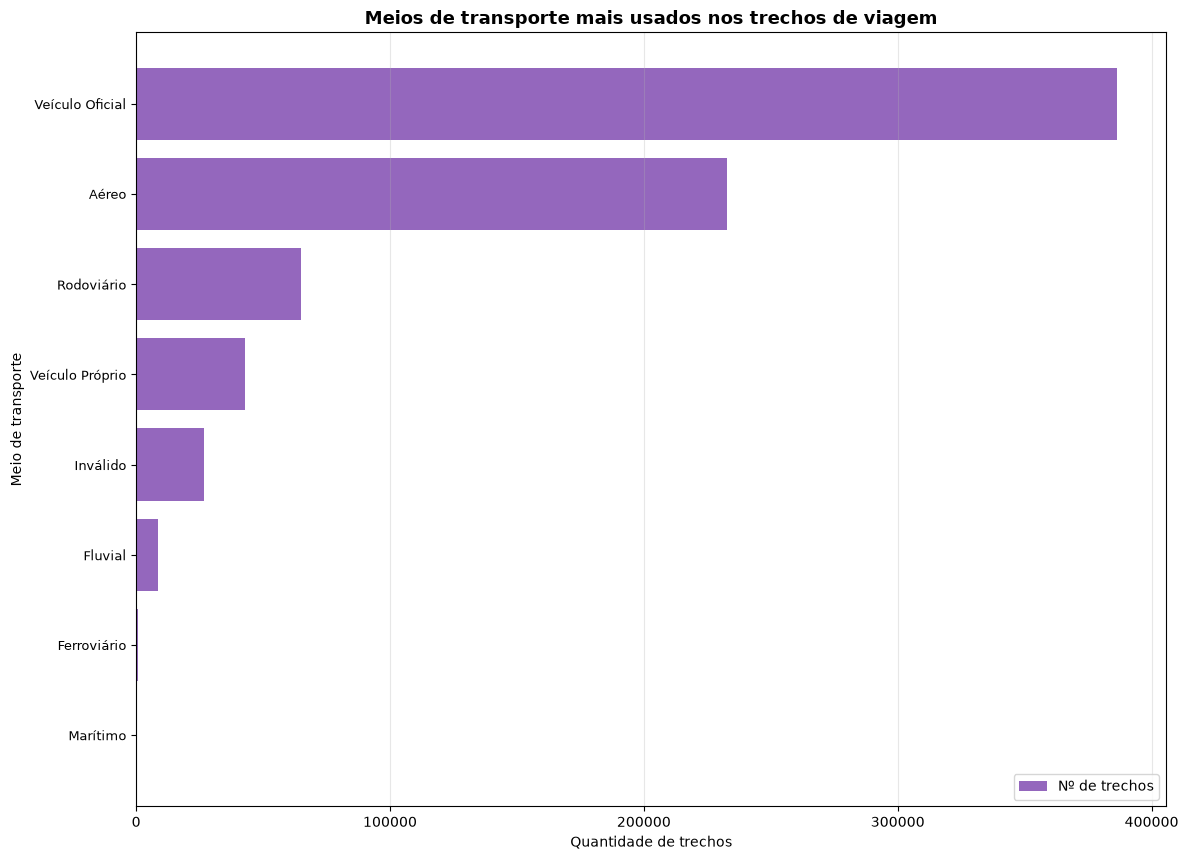

In [11]:
df_b2 = consultar("SELECT * FROM gold_transporte_trecho ORDER BY qtd_trechos DESC")
display(df_b2)
barras_h(df_b2, x="qtd_trechos", y="meio_transporte",
         titulo="Meios de transporte mais usados nos trechos de viagem",
         xlabel="Quantidade de trechos", ylabel="Meio de transporte",
         legenda="Nº de trechos", cor="#9467bd", formato_moeda=False)

## B3. Qual UF de destino aparece em mais trechos?
Mostramos as 10 UFs mais frequentes.

,destino_uf,qtd_trechos,qtd_viagens
0,São Paulo,82722,46392
1,Distrito Federal,79962,72297
2,Minas Gerais,50965,26891
3,Rio de Janeiro,44197,35050
4,Paraná,42603,22263
5,Pará,40044,18138
6,Rio Grande do Sul,38684,20104
7,Mato Grosso do Sul,30516,13332
8,Bahia,28375,14735
9,Pernambuco,28372,16637


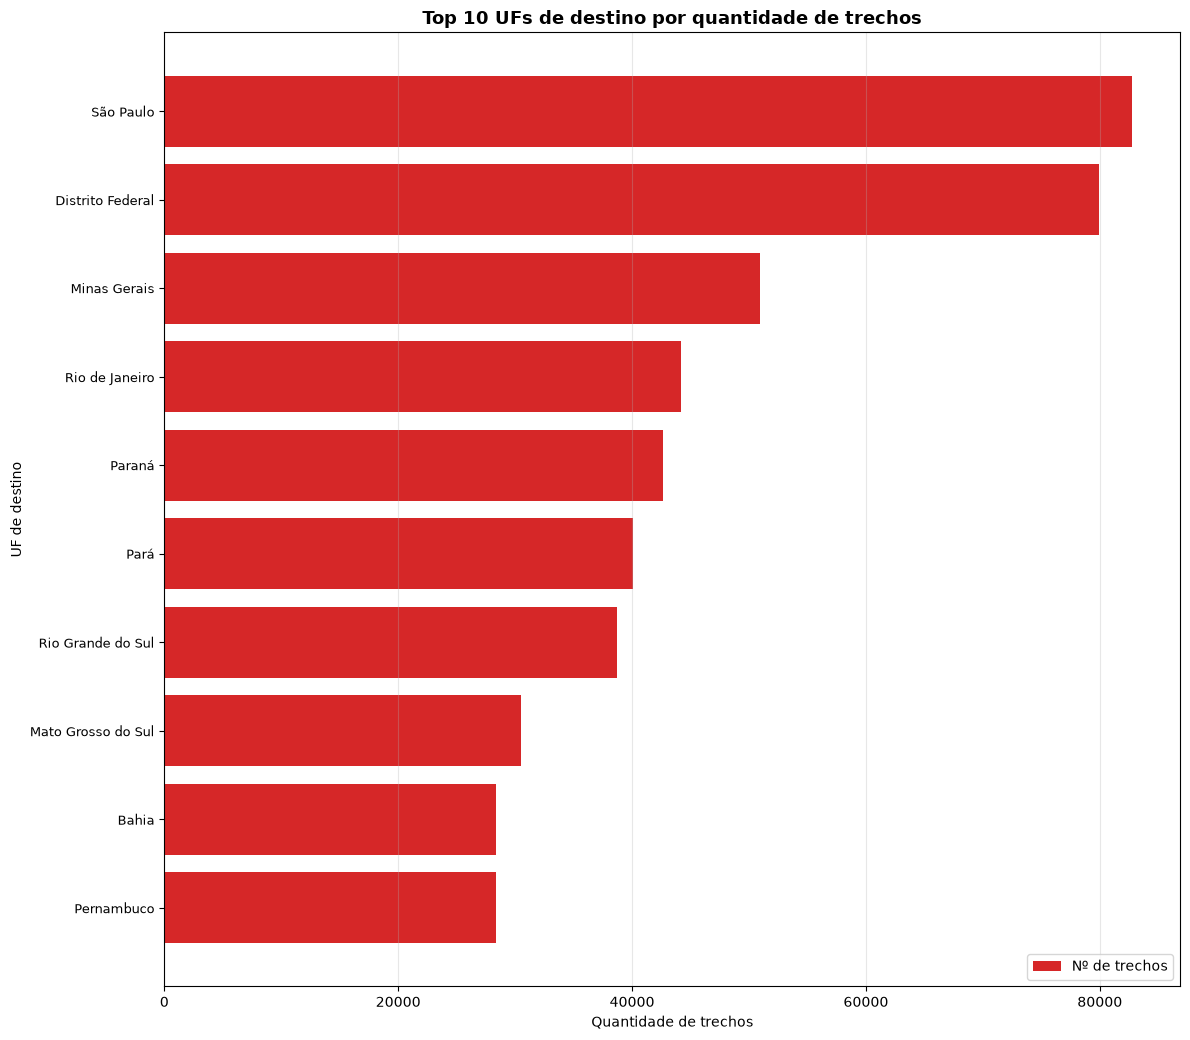

In [12]:
df_b3 = consultar("""
    SELECT * FROM gold_uf_destino
    WHERE destino_uf IS NOT NULL
    ORDER BY qtd_trechos DESC
    LIMIT 10
""")
display(df_b3)
barras_h(df_b3, x="qtd_trechos", y="destino_uf",
         titulo="Top 10 UFs de destino por quantidade de trechos",
         xlabel="Quantidade de trechos", ylabel="UF de destino",
         legenda="Nº de trechos", cor="#d62728", formato_moeda=False)

## B4. Qual órgão pagou mais no total?
Considera o **órgão pagador** (`silver_pagamento`), que pode diferir do órgão superior da viagem.

,nome_orgao_pagador,qtd_viagens,valor_total_pago
0,Fundo Nacional de Segurança Pública,24116,"278,481,047.89"
1,Sigiloso,51550,"200,484,801.68"
2,Comando da Aeronáutica,32336,"81,769,144.77"
3,Instituto Nacional do Seguro Social,7264,"37,427,601.45"
4,Comando do Exército,13285,"36,872,643.95"
5,Ministério da Gestão e da Inovação em Serviços...,9428,"35,541,760.71"
6,Instituto Brasileiro do Meio Ambiente e dos Re...,8809,"31,589,853.15"
7,Ministério das Relações Exteriores - Unidades ...,1927,"25,605,376.38"
8,Receita Federal do Brasil,10063,"23,811,027.00"
9,Ministério da Agricultura e Pecuária - Unidade...,10754,"22,899,880.25"


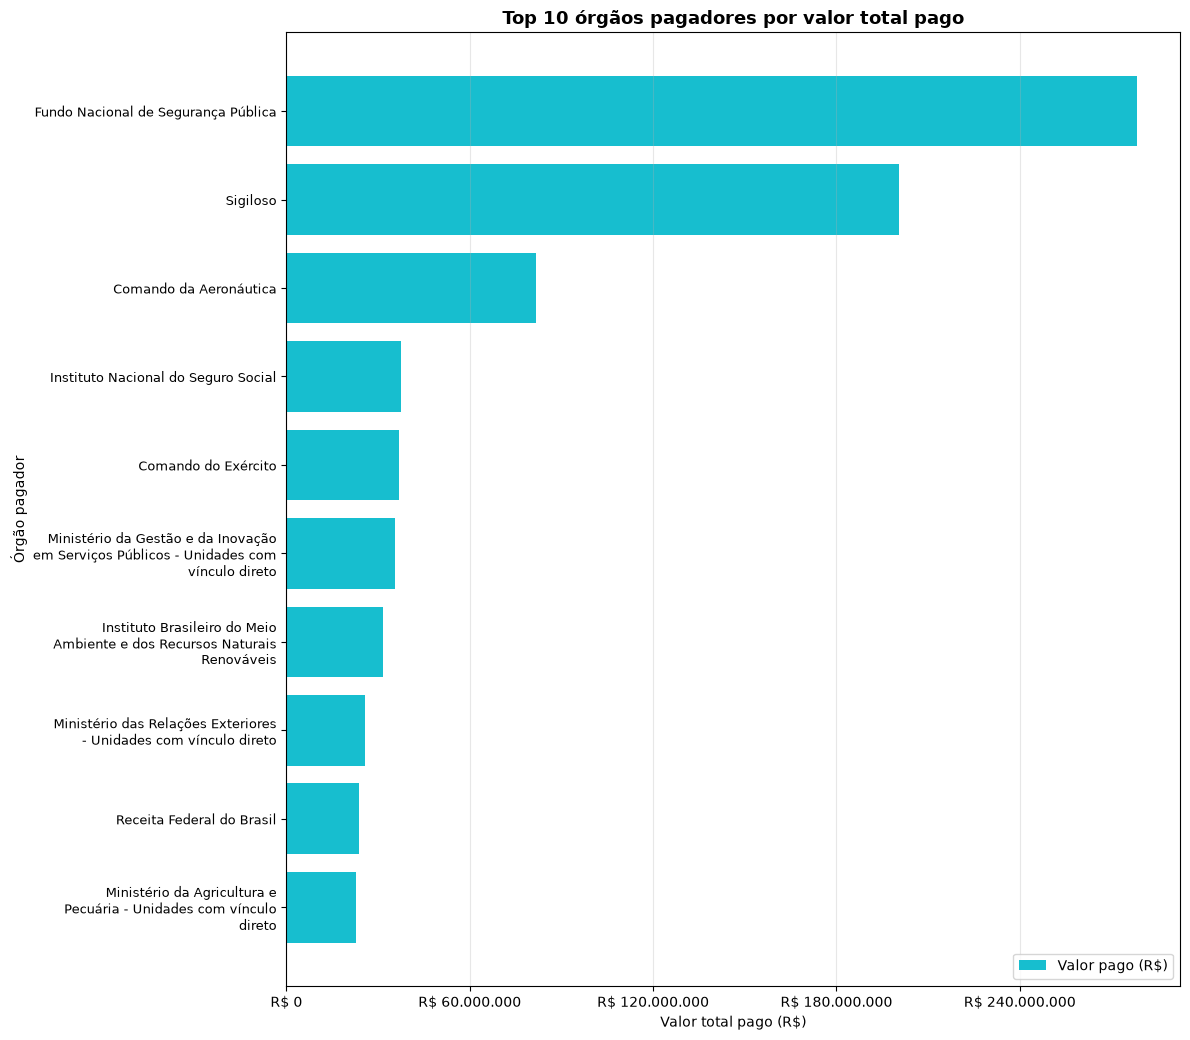

In [13]:
df_b4 = consultar("""
    SELECT * FROM gold_orgao_pagador
    ORDER BY valor_total_pago DESC
    LIMIT 10
""")
display(df_b4)
barras_h(df_b4, x="valor_total_pago", y="nome_orgao_pagador",
         titulo="Top 10 órgãos pagadores por valor total pago",
         xlabel="Valor total pago (R$)", ylabel="Órgão pagador",
         legenda="Valor pago (R$)", cor="#17becf")

## Conclusões e insights

> - Quais órgãos concentram os custos e o que isso sugere?
Os órgãos que concentram os custos são: Ministério da Justiça e Segurança Pública, Ministério da Defesa, Ministério da Educação, Ministério do Meio Ambiente e Mudança do Clima e o Ministério da Previdência Social.

> - A viagem de maior duração e seu custo total? 
A viagem com maior duração é a 20699856 do Ministério da Previdência social.

> - Qual o meio de transporte mais usado nos trechos? 
Veículo oficial

> - Qual UF de destino aparece em mais trechos? 
São Paulo

> - Qual órgão pagou mais no total? 
Fundação Nacional de Segurança Pública